In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from pathlib import Path
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from scipy.signal import fftconvolve
from scipy.stats import gamma
from tqdm import tqdm

DATA  = Path('/content/drive/MyDrive/Brain_alignment/lpp_data')
FUNC  = DATA / 'sub-EN057/func'
ANNOT = DATA / 'annotation/EN'
RUN_SECTION_MAP = {15: 1, 16: 2, 17: 3, 18: 4}
TR = 2.0
LAYERS = [0, 3, 6, 9, 12, 15, 18, 21, 24]  # 0=embedding, 24=last

Mounted at /content/drive


In [ ]:
word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')

alignments    = {}
n_trs_per_run = {}
bold_stack    = []

for run, sec in RUN_SECTION_MAP.items():
    img   = nib.load(str(FUNC / f'sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'))
    n_trs = img.shape[3]
    n_trs_per_run[run] = n_trs
    bold_stack.append(img.get_fdata().reshape(-1, n_trs).T)

    sec_words = word_info[word_info['section'] == sec].copy()
    sec_words['word']     = sec_words['word'].fillna('').astype(str)
    sec_words['TR_index'] = (sec_words['onset'] / TR).astype(int).clip(upper=n_trs-1)
    alignments[run] = sec_words

bold_all = np.concatenate(bold_stack, axis=0)
mask     = bold_all.std(axis=0) > 0
bold_all = bold_all[:, mask]
print(f"BOLD: {bold_all.shape}")

BOLD: (1239, 129385)


In [ ]:
tokenizer = GPT2Tokenizer.from_pretrained('gpt2-medium')
model     = GPT2Model.from_pretrained('gpt2-medium')
model.eval()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
print(f"Device: {device}")

def extract_layer_embeddings(words, layers):
    """Extract hidden states at multiple layers, full context."""
    results = {l: [] for l in layers}

    for i, word in enumerate(tqdm(words, desc="Extracting")):
        ctx_words = words[:i+1]
        inputs    = tokenizer(' '.join(ctx_words), return_tensors='pt').to(device)
        if inputs['input_ids'].shape[1] > 1024:
            inputs = {k: v[:, -1024:] for k, v in inputs.items()}

        with torch.no_grad():
            out = model(**inputs, output_hidden_states=True)

        for l in layers:
            emb = out.hidden_states[l][0, -1, :].cpu().numpy()
            results[l].append(emb)

    return {l: np.array(v) for l, v in results.items()}

# Extract for all 4 runs
layer_embeddings = {}
for run, sec in RUN_SECTION_MAP.items():
    print(f"\n=== Run {run} (section {sec}) ===")
    words = alignments[run]['word'].tolist()
    layer_embeddings[run] = extract_layer_embeddings(words, LAYERS)

print("Done.")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

... (7 outputs left out)

Extracting: 100%|██████████| 1852/1852 [05:16<00:00,  5.84it/s]



=== Run 18 (section 4) ===


Extracting: 100%|██████████| 1624/1624 [04:27<00:00,  6.07it/s]

Done.


In [ ]:
def hrf_kernel(tr=2.0, n_trs=20):
    t = np.arange(0, n_trs * tr, tr)
    h = gamma.pdf(t, 6) - 0.35 * gamma.pdf(t, 16)
    return h / h.max()

def convolve_hrf(X):
    h   = hrf_kernel()
    out = np.zeros_like(X)
    for i in range(X.shape[1]):
        conv = fftconvolve(X[:, i], h, mode='full')
        out[:, i] = conv[:X.shape[0]]
    return out

def encode_model(X, Y, n_components=50, n_splits=5):
    X_pca = PCA(n_components=n_components).fit_transform(
                StandardScaler().fit_transform(X))
    kf = KFold(n_splits=n_splits, shuffle=False)
    r2_folds = []
    for tr_idx, te_idx in kf.split(X_pca):
        ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000])
        ridge.fit(X_pca[tr_idx], Y[tr_idx])
        r2_folds.append(r2_score(Y[te_idx], ridge.predict(X_pca[te_idx]),
                                  multioutput='raw_values'))
    return np.mean(r2_folds, axis=0)

layer_r2 = {}
for layer in LAYERS:
    # Stack TR-averaged embeddings across runs
    tr_mats = []
    for run in RUN_SECTION_MAP:
        aln    = alignments[run]
        emb    = layer_embeddings[run][layer]
        n_trs  = n_trs_per_run[run]
        mat    = np.zeros((n_trs, 1024))
        counts = np.zeros(n_trs)
        for i, tr_idx in enumerate(aln['TR_index'].values):
            mat[tr_idx]    += emb[i]
            counts[tr_idx] += 1
        m = counts > 0
        mat[m] /= counts[m, None]
        tr_mats.append(mat)

    X = convolve_hrf(np.concatenate(tr_mats, axis=0))
    r2 = encode_model(X, bold_all)
    layer_r2[layer] = r2
    pos = r2 > 0
    print(f"Layer {layer:>2}: mean R²={r2[pos].mean():.4f}, "
          f"positive voxels={pos.sum()} ({100*pos.mean():.1f}%)")

Layer  0: mean R²=0.0442, positive voxels=47 (0.0%)
Layer  3: mean R²=0.0595, positive voxels=101 (0.1%)
Layer  6: mean R²=0.0550, positive voxels=98 (0.1%)
Layer  9: mean R²=0.0505, positive voxels=79 (0.1%)
Layer 12: mean R²=0.0543, positive voxels=96 (0.1%)
Layer 15: mean R²=0.0600, positive voxels=96 (0.1%)
Layer 18: mean R²=0.0581, positive voxels=69 (0.1%)
Layer 21: mean R²=0.0541, positive voxels=114 (0.1%)
Layer 24: mean R²=0.0661, positive voxels=174 (0.1%)


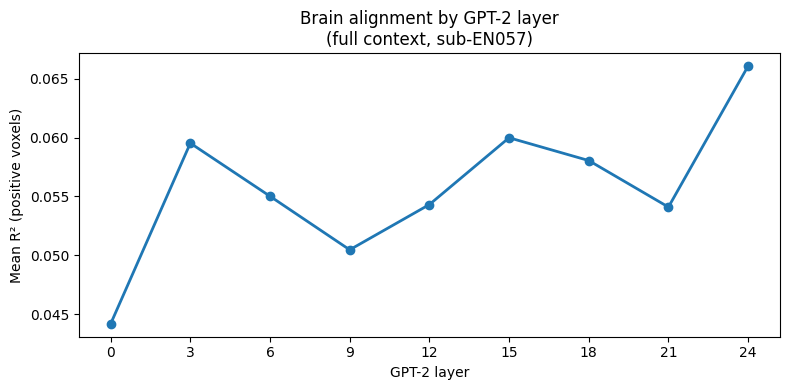

Saved.


In [ ]:
means = [layer_r2[l][layer_r2[l] > 0].mean() for l in LAYERS]

plt.figure(figsize=(8, 4))
plt.plot(LAYERS, means, marker='o', linewidth=2)
plt.xlabel('GPT-2 layer')
plt.ylabel('Mean R² (positive voxels)')
plt.title('Brain alignment by GPT-2 layer\n(full context, sub-EN057)')
plt.xticks(LAYERS)
plt.tight_layout()
plt.savefig(DATA / 'layer_sweep_r2.png', dpi=150)
plt.show()

np.savez(DATA / 'layer_sweep_r2.npz',
         layers=np.array(LAYERS),
         **{f'layer_{l}': layer_r2[l] for l in LAYERS})
print("Saved.")